In [1]:
import geomeppy

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

from gen_function_make_geometry_idf_sample_initial import make_geometry_idf_sample_distr
from ep_function_make_enriched_idf import make_enriched_idf
from ep_function_run_simulations import function_run_simulations
from ep_function_read_output import function_read_output

from surr_function_make_input_vector_and_predict import function_make_input_vector_and_predict
from surr_function_make_input_vector_and_predict_over_time import function_make_input_vector_and_predict_over_time

from scipy.stats import t
from vis_function_building_assessment_longterm import function_building_assessment_longterm
from vis_function_neighborhood_maps import function_neighborhood_maps
from vis_function_cumulative_sums import calculate_mean_ci_by_year, function_cumulative_sums_neighborhood

[[(1.159, 8.901), (0.0, 3.651), (8.12, 1.888), (10.068, 1.433), (10.229, 2.062), (18.33, 0.0), (19.01, 2.673), (14.935, 3.711), (15.12, 4.436), (13.107, 4.949), (13.377, 6.012), (9.06, 7.11)]]
5.73
2
Polygon2D([Vector2D(0.0, 8.901), Vector2D(0.0, 0.0), Vector2D(19.01, 0.0), Vector2D(19.01, 8.901)])


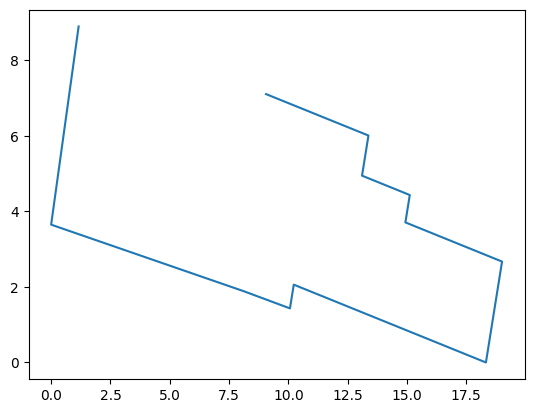

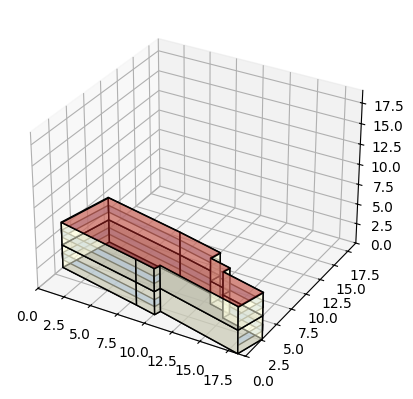

None


In [4]:
# Sample for a specific BAG Pand ID (retrieve based on the building address from: https://bagviewer.kadaster.nl/lvbag/bag-viewer)
bag_pand_id ='["0599100000614202"]'
n_sim=2
(idf, building, records_init_singleb) = make_geometry_idf_sample_distr(bag_pand_id, n_sim)
idf = make_enriched_idf(idf, building, records_init_singleb)

print(building.bag_vertices)
print(building.bag_building_height)
print(building.bag_num_floor)

import matplotlib.pyplot as plt
x, y = zip(*building.bag_vertices[0])
plt.plot(x, y)

print(idf.bounding_box())
print(idf.view_model())

In [4]:
# EnergyPlus path
# Enrich the idf files based on the properties of each path, run the simulations & read the output
output_dir = "./simulation_files"
epw_path = './INP_epw_file/NLD_ZH_Rotterdam.The.Hague.AP.063440_TMYx.2009-2023.epw'

make_enriched_idf(idf, building, records_init_singleb)
function_run_simulations(output_dir, epw_path)
df_records_ep = function_read_output("./simulation_files", records_init_singleb) 
# Heating outputs & Underheating hours are calculated for heating season (October to March)
# Cooling outputs & Overheating hours are calculated for cooling season (April to September)

EnergyPlusRunError: 

Contents of EnergyPlus error file at C:\Users\shaad\Repositories\de-cist-backend\retrpred\src\simulation_files\Outputs\599200000225961.err
Program Version,EnergyPlus, Version 23.1.0-87ed9199d4, YMD=2026.11.05 13:15,
   ** Severe  ** <root>[BuildingSurface:Detailed][Block BuildingBlock1 Storey 0 Ceiling 0001] - Missing required property 'construction_name'.
   **  Fatal  ** Errors occurred on processing input file. Preceding condition(s) cause termination.
   ...Summary of Errors that led to program termination:
   ..... Reference severe error count=1
   ..... Last severe error=<root>[BuildingSurface:Detailed][Block BuildingBlock1 Storey 0 Ceiling 0001] - Missing required property 'construction_name'.
   ************* Warning:  Node connection errors not checked - most system input has not been read (see previous warning).
   ************* Fatal error -- final processing.  Program exited before simulations began.  See previous error messages.
   ************* En

In [5]:
# Surrogate path - Assess building performance on year 0
# Create input vector, assess for building performance
records_res_singleb = function_make_input_vector_and_predict(idf, building, records_init_singleb)
print(records_res_singleb)

[{'bag_adres_id': np.int64(599200000225977), 'bag_pand_id': '["0599100000614202"]', 'sim': 0, 'year': 0, 'heating_dem_m2': 309.87548828125, 'heating_gas_m2': 0.0, 'heating_elec_m2': 0.0, 'heating_distr_heat_m2': 308.635986328125, 'cooling_dem_m2': 2.240079164505005, 'cooling_elec_m2': 1.347830447858592, 'underheat_m2': 0.0, 'overheat_m2': 0.0, 'r_wall': 0.025, 'r_wall_ins': 0.02439024390243903, 'r_roof': 4.225000000000001, 'r_roof_ins': 3.5957446808510647, 'r_floor': 0.025, 'r_floor_ins': 0.018867924528301886, 'ageing_wall': 0.025, 'ageing_roof': 0.17500000000000002, 'ageing_floor': 0.32500000000000007, 'year_wall': 0, 'year_roof': 4, 'year_floor': 88, 'year_window': 2, 'year_gas_boiler': 4, 'year_heat_pump': 1, 'year_airco': 31, 'u_glazing_type': 1, 'u_window': 2.73, 'shgc': 0.7, 'inf_rate': 0.0015, 'boiler_eff': 0.89426972309375, 'hp_cop': 4.85, 'dx_cop': 2.0, 'heating_system': 'district_heating', 'cooling_system': 'dx_airco', 'carbon emissions': 43.57025664596361}, {'bag_adres_id': 

In [17]:
# Surrogate path - Assess performance for building lifetime
# Connect with time-dependent degradation models & retrofit plans, Create input vector & Assess performance along building lifetime
building_lifetime = 2

# Create retrofit plan (Initially do-nothing for all years and then change strategy for specific component and year)
components = ["wall", "roof", "floor", "window", "heating_system", "cooling_system", "inf_rate"]
retrofit_plan = {component: ["do_nothing"] * 70 for component in components}
retrofit_plan["wall"][1] = "retrofit_6.2"
retrofit_plan["roof"][1] = "retrofit_8.3"
retrofit_plan["floor"][1] = "retrofit_5.7"
retrofit_plan["window"][1] = "retrofit_3"
retrofit_plan["inf_rate"][1] = "retrofit_0.0004"
retrofit_plan["heating_system"][1] = "retrofit_gas_boiler"
retrofit_plan["cooling_system"][1] = "retrofit_dx_airco"

records_res_singleb_time = function_make_input_vector_and_predict_over_time(idf, building, records_init_singleb, building_lifetime, retrofit_plan)
print(records_res_singleb_time[-1])

{'bag_adres_id': np.int64(599200000225977), 'bag_pand_id': '["0599100000614202"]', 'sim': 1, 'year': 1, 'heating_dem_m2': 28.129119873046875, 'heating_gas_m2': 29.461551666259766, 'heating_elec_m2': 0.0, 'heating_distr_heat_m2': 0.0, 'cooling_dem_m2': 73.3809814453125, 'cooling_elec_m2': 20.135074849133783, 'underheat_m2': 0.0, 'overheat_m2': 0.0, 'r_wall': 6.2, 'r_wall_ins': 6.2, 'r_roof': 8.3, 'r_roof_ins': 8.3, 'r_floor': 5.7, 'r_floor_ins': 5.7, 'ageing_wall': 0.0, 'ageing_roof': 0.0, 'ageing_floor': 0.0, 'year_wall': 0, 'year_roof': 0, 'year_floor': 0, 'year_window': 0, 'year_gas_boiler': 0, 'year_heat_pump': 0, 'year_airco': 0, 'u_glazing_type': 3, 'u_window': 0.56, 'shgc': 0.5, 'inf_rate': 0.0002165674066053059, 'boiler_eff': 0.95, 'hp_cop': 5.0, 'dx_cop': 4.0, 'heating_system': 'gas_boiler', 'cooling_system': 'dx_airco', 'carbon_emissions': 11.818818322812483}


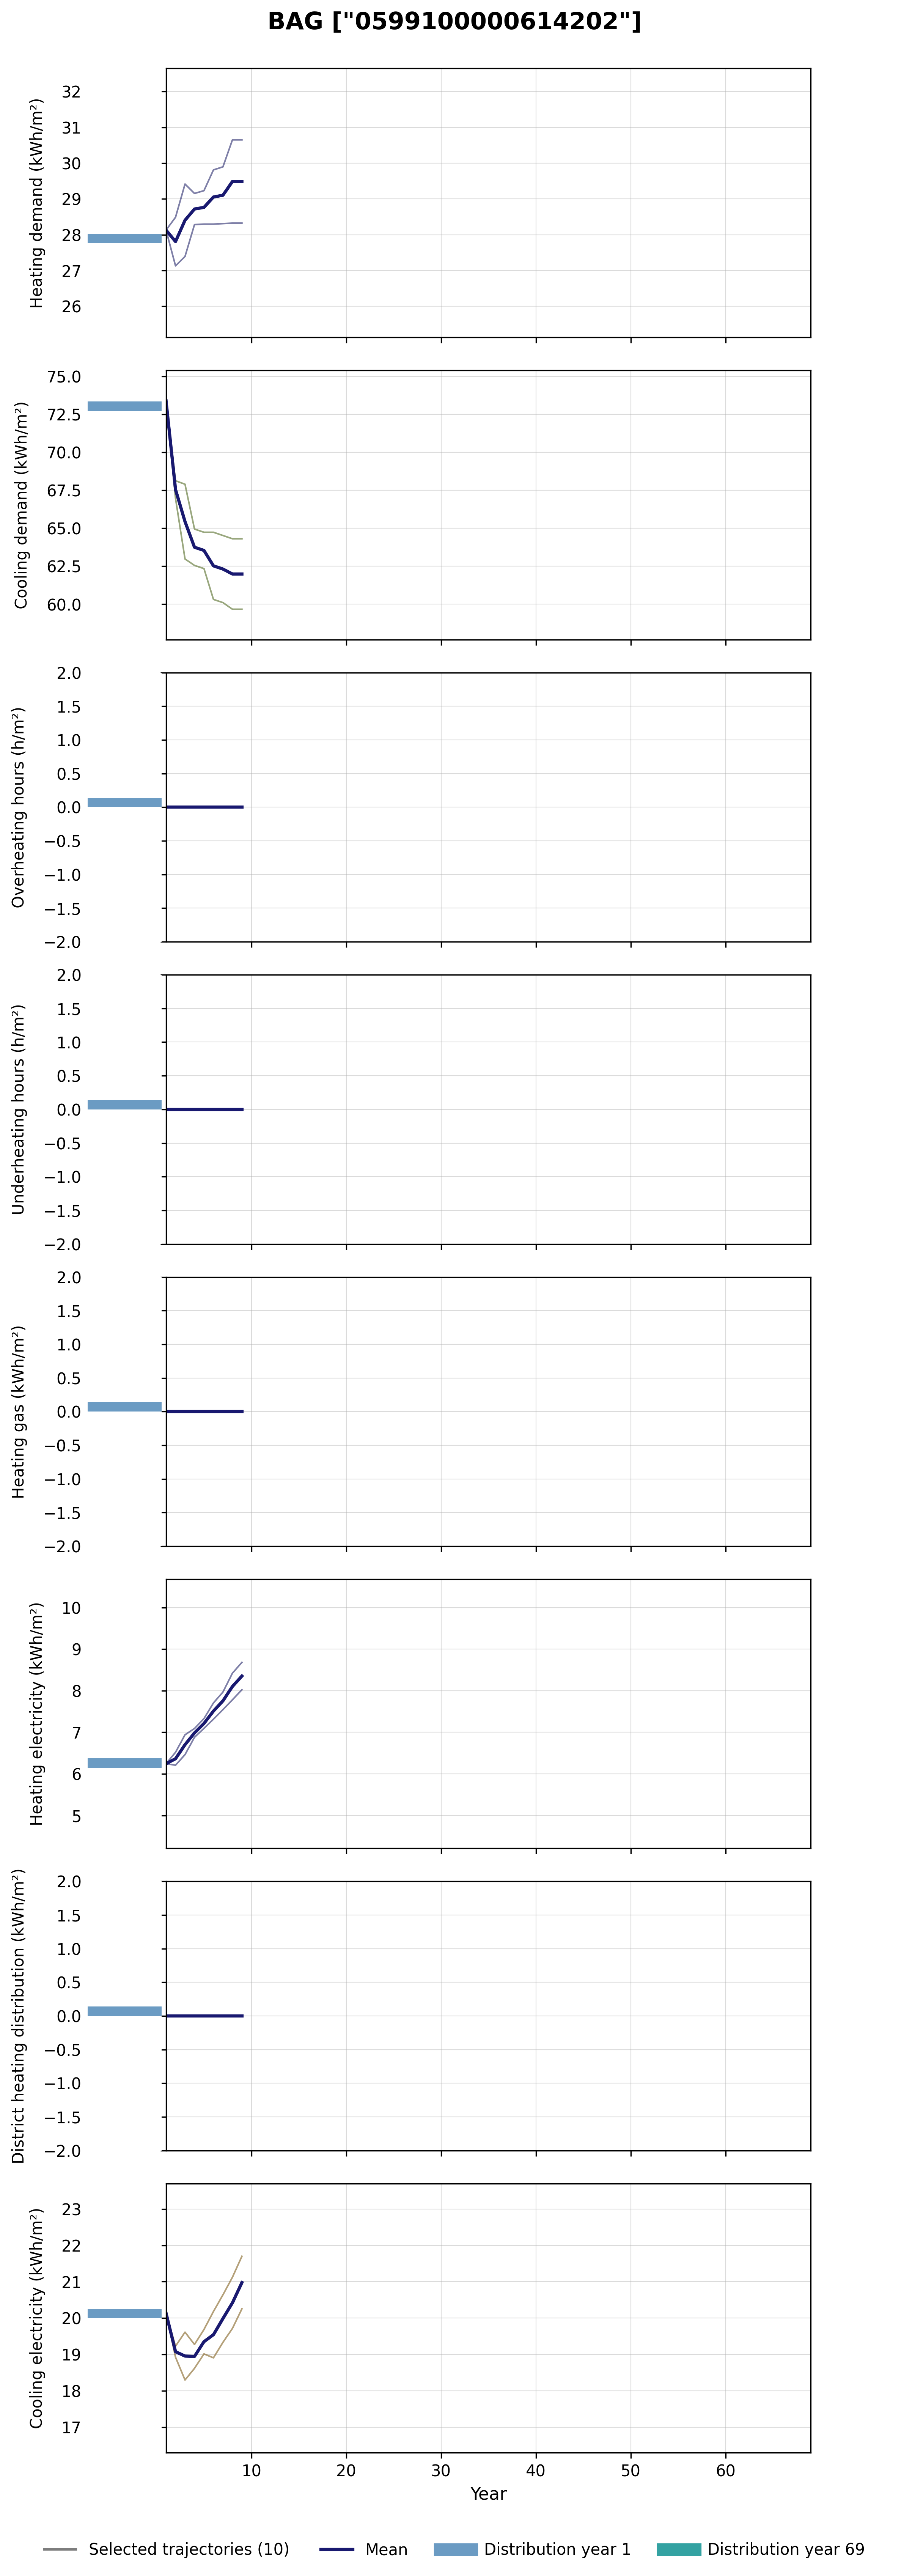

In [6]:
# Visualize probabilistic assessment for single building in the long term
function_building_assessment_longterm(records_res_singleb_time, bag_pand_id)

In [8]:
# Surrogate path - Assess performance for multiple buildings in the long-term

# Output columns
output_cols = [
    "heating_dem_m2",
    "cooling_dem_m2",
    "heating_gas_m2",
    "heating_elec_m2",
    "heating_distr_heat_m2",
    "cooling_elec_m2",
    "underheat_m2",
    "overheat_m2",
    "carbon_emissions"
]

# Create a retrofit plan (Initially do-nothing for all years and then change strategy for specific component and year)
components = ["wall", "roof", "floor", "window", "heating_system", "cooling_system", "inf_rate"]
retrofit_plan = {component: ["do_nothing"] * 70 for component in components}
retrofit_plan["wall"][1] = "retrofit_6.2"
retrofit_plan["roof"][1] = "retrofit_8.3"
retrofit_plan["floor"][1] = "retrofit_5.7"
retrofit_plan["window"][1] = "retrofit_3"
retrofit_plan["inf_rate"][1] = "retrofit_0.0004"
retrofit_plan["heating_system"][1] = "retrofit_heat_pump"
retrofit_plan["cooling_system"][1] = "retrofit_dx_airco"

# Read file with building IDs to test (here they belong to the same neighborhood)
gdf_pands = pd.read_csv("pands_kralingseveer.csv")
n_buildings = len(gdf_pands)

n_samples = 5
n_years =  10
year_values = list(range(0, n_years)) 
n_outputs = len(output_cols)

# Initiate the numpy arrays to collect the outputs per building, per year
mean_by_building_year_output = np.zeros((n_buildings, n_years, n_outputs), dtype=np.float32)
lower_ci_by_building_year_output = np.zeros((n_buildings, n_years, n_outputs), dtype=np.float32)
upper_ci_by_building_year_output = np.zeros((n_buildings, n_years, n_outputs), dtype=np.float32)
se_by_building_year_output = np.zeros((n_buildings, n_years, n_outputs), dtype=np.float32)

# Predict performance per building and calculate mean and confidence intervals per year
for b_idx, row in gdf_pands.iterrows():
    raw_id = str(row["bag_pand_id"])
    print('processing', raw_id)
    print("-make idf...")
    (idf, building, records_init) = make_geometry_idf_sample_distr(raw_id, n_samples)  # This is slow...
    print("-predict...")
    records_res_time = function_make_input_vector_and_predict_over_time(idf, building, records_init, n_years, retrofit_plan)  # And this is slow...
    print("-finish...")
    df_records_res_time = pd.DataFrame(records_res_time)
    stats = calculate_mean_ci_by_year(df_records_res_time, output_cols, year_values, confidence=0.95)
    mean_by_building_year_output[b_idx, :, :] = stats["mean"]
    lower_ci_by_building_year_output[b_idx, :, :] = stats["lower"]
    upper_ci_by_building_year_output[b_idx, :, :] = stats["upper"]
    se_by_building_year_output[b_idx, :, :] = stats["se"]
    

# Compute sum of means at neighborhood scale and confidence intervals 
t_crit = t.ppf(0.975, n_samples)
city_sum_mean = np.sum(mean_by_building_year_output, axis=0)
city_se = np.sqrt(np.sum(se_by_building_year_output ** 2, axis=0))
city_ci_half_width = t_crit * city_se
city_lower = city_sum_mean - city_ci_half_width
city_upper = city_sum_mean + city_ci_half_width

processing ["0599100000018491"]
-make idf...
-predict...
-finish...
processing ["0599100000018493"]
-make idf...
-predict...
-finish...
processing ["0599100000021102"]
-make idf...
-predict...
-finish...
processing ["0599100000021103"]
-make idf...


KeyboardInterrupt: 

In [7]:
# Create neighborhood maps for each output variable showing performance with building-level resolution
year_idx = 0
function_neighborhood_maps(gdf_pands, mean_by_building_year_output, year_idx)

NameError: name 'gdf_pands' is not defined

In [ ]:
# Visualize cumulative sum and confidence intervals for the whole neighborhood
function_cumulative_sums_neighborhood(city_sum_mean, city_lower, city_upper, n_years)